# UTS Penambangan Data — Regresi Linier LP2B
Dataset: Luas Lahan Sawah yang Ditetapkan sebagai LP2B (Capaian Penetapan LBS ke dalam LP2B, Triwulan I 2026, sheet *Kabupaten*).

Target (y): Total Penetapan LP2B (Ha) — Fitur (X): LBS 2024 Total (Ha).

In [1]:
import pandas as pd, numpy as np, warnings
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
warnings.filterwarnings("ignore")

FILE = "63_Luas_Lahan_Sawah_yang_Ditetapkan_sebagai_LP2B (1).xlsx"   # sesuaikan nama/path file
df = pd.read_excel(FILE, sheet_name="Kabupaten", header=None, skiprows=5, usecols=range(15))
df.columns = ["no","pase","prov","kab","lbs2019","kh","diluar","lbs2024","ket","luas","ds","tds","total","jenis","noreg"]
d = df[pd.to_numeric(df.no, errors="coerce").notna()].copy()   # buang baris total/keterangan di bawah tabel
print(d.shape)

(513, 15)


## 1. Kondisi awal data (missing value)

In [2]:
num = ["lbs2019","kh","diluar","lbs2024","luas","ds","tds","total"]
# perbaiki sel bertipe teks berkoma desimal, mis. "2993,73"
for c in num:
    d[c] = pd.to_numeric(d[c].astype(str).str.replace(",", ".").replace("nan", np.nan), errors="coerce")
miss = d.isna().sum().to_frame("jumlah"); miss["persen"] = (miss.jumlah/len(d)*100).round(2)
miss[miss.jumlah>0]

,jumlah,persen
lbs2019,27,5.26
luas,19,3.70
ds,261,50.88
tds,366,71.35
total,9,1.75
jenis,19,3.70
noreg,19,3.70


## 2. Data Preparation

In [3]:
# populasi pemodelan: kab/kota yang sudah menetapkan luasan LP2B (DS/D)
m = d[d.ket.isin(["DS","D"])].copy()
# hapus target kosong dan baris tidak konsisten (0)
mm = m.dropna(subset=["total"])
mm = mm[(mm.total>0) & (mm.lbs2024>0)].copy()
print("baris sebelum outlier:", len(mm))

# outlier IQR -> capping
def batas(s):
    q1,q3 = s.quantile([.25,.75]); i = q3-q1
    return max(q1-1.5*i,0), q3+1.5*i
mc = mm.copy()
for c in ["lbs2024","total"]:
    lo,hi = batas(mm[c])
    print(c, "outlier:", int(((mm[c]<lo)|(mm[c]>hi)).sum()), "batas atas:", round(hi,2))
    mc[c] = mm[c].clip(lo,hi)
mc[["lbs2024","total"]].describe()

baris sebelum outlier: 390
lbs2024 outlier: 20 batas atas: 60851.84
total outlier: 23 batas atas: 47454.61


,lbs2024,total
count,390.000000,390.000000
mean,16333.717069,13183.248122
std,17600.811493,13988.664035
min,22.948921,2.990000
25%,2136.859200,1681.511275
50%,8917.355972,7940.393390
75%,25622.852376,19990.750000
max,60851.842141,47454.608088


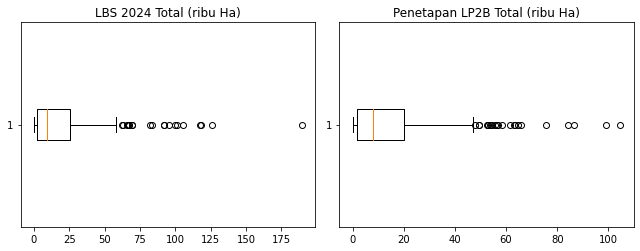

In [4]:
fig, ax = plt.subplots(1,2, figsize=(9,3.6))
ax[0].boxplot(mm.lbs2024/1000, vert=False); ax[0].set_title("LBS 2024 Total (ribu Ha)")
ax[1].boxplot(mm.total/1000, vert=False);   ax[1].set_title("Penetapan LP2B Total (ribu Ha)")
plt.tight_layout(); plt.show()

## 3. Pemodelan Regresi Linier

In [5]:
X = mc[["lbs2024"]]; y = mc["total"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Data latih / uji :", len(X_train), "/", len(X_test))
print(f"Intercept (b0)   : {model.intercept_:,.2f}")
print(f"Koefisien (b1)   : {model.coef_[0]:.4f}")
print(f"R2               : {r2_score(y_test, y_pred):.4f}")
print(f"MAE              : {mean_absolute_error(y_test, y_pred):,.2f} Ha")
print(f"RMSE             : {mean_squared_error(y_test, y_pred)**0.5:,.2f} Ha")

Data latih / uji : 312 / 78
Intercept (b0)   : 494.24
Koefisien (b1)   : 0.7757
R2               : 0.9442
MAE              : 2,014.21 Ha
RMSE             : 3,519.44 Ha


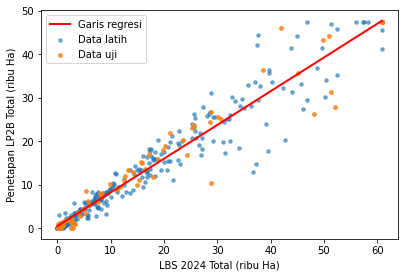

In [6]:
plt.figure(figsize=(6.4,4.2))
plt.scatter(X_train/1000, y_train/1000, s=12, alpha=.6, label="Data latih")
plt.scatter(X_test/1000,  y_test/1000,  s=14, alpha=.8, label="Data uji")
xs = np.linspace(0, X.values.max(), 50).reshape(-1,1)
plt.plot(xs/1000, model.predict(pd.DataFrame(xs, columns=["lbs2024"]))/1000, "r", lw=2, label="Garis regresi")
plt.xlabel("LBS 2024 Total (ribu Ha)"); plt.ylabel("Penetapan LP2B Total (ribu Ha)"); plt.legend(); plt.show()

## 4. Sampel 15 data untuk perhitungan manual (Soal 2)

In [7]:
s = mc.sample(15, random_state=7).sort_values("lbs2024").reset_index(drop=True)
s["x"] = (s.lbs2024/1000).round(2); s["y"] = (s.total/1000).round(2)
n = len(s); Sx, Sy, Sxx, Sxy = s.x.sum(), s.y.sum(), (s.x**2).sum(), (s.x*s.y).sum()
b1 = (n*Sxy - Sx*Sy)/(n*Sxx - Sx**2); b0 = Sy/n - b1*Sx/n
yh = b0 + b1*s.x; r2 = 1 - ((s.y-yh)**2).sum()/((s.y-s.y.mean())**2).sum()
print(f"b0={b0:.4f}  b1={b1:.4f}  R2={r2:.4f}")
s[["prov","kab","x","y"]]

b0=0.8730  b1=0.6592  R2=0.8622


,prov,kab,x,y
0,Papua,Waropen,0.03,0.02
1,Kepulauan Bangka Belitung,Bangka Tengah,0.26,0.16
2,Aceh,Kota Langsa,1.10,0.90
3,Kalimantan Utara,Malinau,1.82,1.71
4,Kepulauan Bangka Belitung,Bangka,2.26,2.44
5,Nusa Tenggara Timur,Sabu Raijua,2.46,2.39
6,Jambi,Tebo,5.25,4.94
7,Bengkulu,Seluma,6.49,8.33
8,Bali,Tabanan,18.90,16.01
9,Sumatera Utara,Langkat,20.23,19.03
